In [1]:

import pandas as pd

file_path = r"D:\raw data\Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# 1. Dataset overview
print("Dataset shape:", df.shape)

# 2. Column names and data types
print("\nColumn names and data types:")
df.info()

# 3. Missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 4. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Churn distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


Dataset shape: (7043, 21)

Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null  

In [ ]:

# Original dataset safe copy
df_clean = df.copy()

# TotalCharges ko numeric mein convert karo
import pandas as pd

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Data quality report
print("Missing values after conversion:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nCleaned dataset shape:", df_clean.shape)

print("\nTotalCharges data type:",
      df_clean["TotalCharges"].dtype)


Missing values after conversion:
TotalCharges    11
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (7043, 21)

TotalCharges data type: float64


In [4]:

# Check rows with missing TotalCharges
print("Rows with missing TotalCharges:")
display(df_clean[df_clean["TotalCharges"].isna()])

# Remove rows with missing TotalCharges
df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()

# Verify the cleaned data
print("New dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())


Rows with missing TotalCharges:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


New dataset shape: (7032, 21)
Remaining missing values: 0


Customer churn counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Customer churn percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


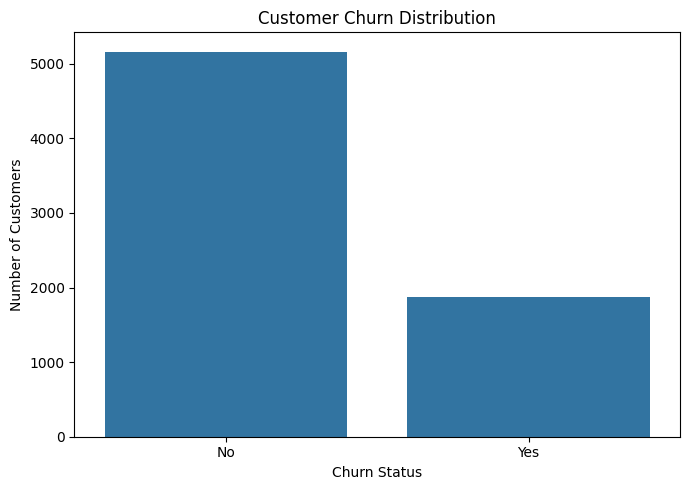

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Customer churn count
print("Customer churn counts:")
print(df_clean["Churn"].value_counts())

# Churn percentage
churn_pct = df_clean["Churn"].value_counts(normalize=True) * 100

print("\nCustomer churn percentage:")
print(churn_pct.round(2))

# Visualization
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


Churn percentage by contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


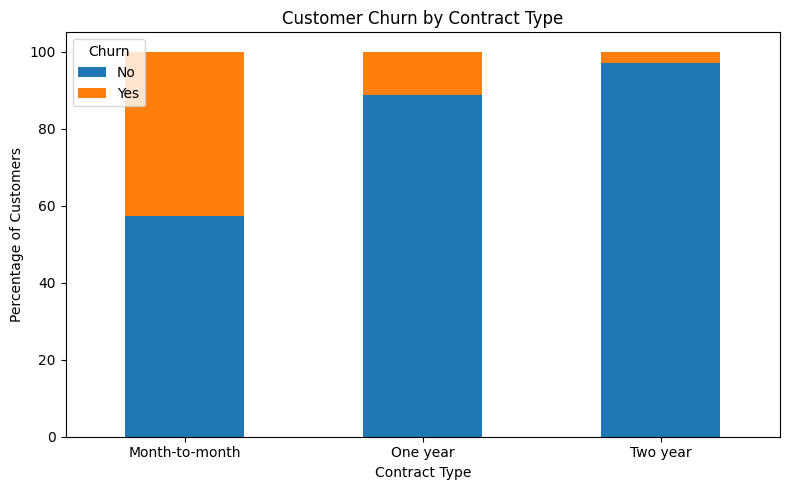

In [6]:

# Churn rate by contract type
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print("Churn percentage by contract type:")
display(contract_churn.round(2))

# Visualization
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Tenure analysis:


,mean,median,count
Churn,,,
No,37.65,38.0,5163
Yes,17.98,10.0,1869


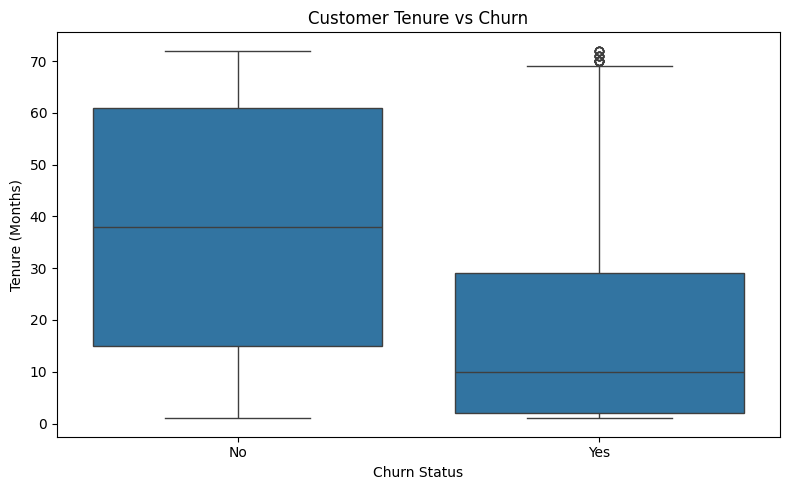

In [7]:

# Average tenure for churned vs retained customers
tenure_analysis = df_clean.groupby("Churn")["tenure"].agg(
    ["mean", "median", "count"]
)

print("Tenure analysis:")
display(tenure_analysis.round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()


Monthly charges analysis:


,mean,median,count
Churn,,,
No,61.31,64.45,5163
Yes,74.44,79.65,1869


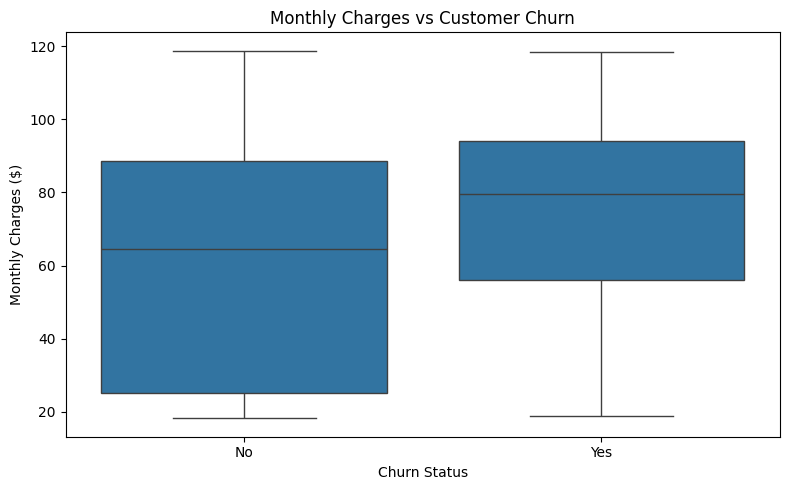

In [8]:

# Monthly charges by churn status
charges_analysis = df_clean.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

print("Monthly charges analysis:")
display(charges_analysis.round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()


In [9]:

from sklearn.model_selection import train_test_split

# Features (X) and target (y)
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (5625, 19)
Testing features: (1407, 19)

Training target distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1033
1     374
Name: count, dtype: int64


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Preprocess numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Build the complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))


Model training completed successfully!
Numerical columns: 4
Categorical columns: 15


Model Evaluation Results
------------------------------
Accuracy:  0.804
Precision: 0.648
Recall:    0.572
F1-score:  0.608

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



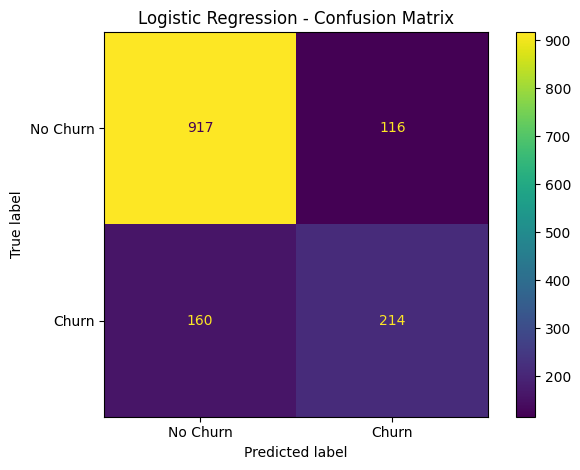

In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict churn on unseen test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
print("Model Evaluation Results")
print("-" * 30)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:

from sklearn.metrics import roc_auc_score

# Predicted churn probabilities
y_proba = model.predict_proba(X_test)[:, 1]

print("FINAL MODEL SUMMARY")
print("=" * 35)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


FINAL MODEL SUMMARY
Accuracy:  0.804
Precision: 0.648
Recall:    0.572
F1-score:  0.608
ROC-AUC:   0.836

Confusion Matrix:
[[917 116]
 [160 214]]


In [13]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Probability of churn
y_proba = model.predict_proba(X_test)[:, 1]

# Compare thresholds
for threshold in [0.5, 0.4, 0.3]:
    y_threshold = (y_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_test, y_threshold), 3
    ))
    print("Recall:", round(
        recall_score(y_test, y_threshold), 3
    ))
    print("F1-score:", round(
        f1_score(y_test, y_threshold), 3
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_threshold))




Threshold: 0.5
Precision: 0.648
Recall: 0.572
F1-score: 0.608
Confusion matrix:
[[917 116]
 [160 214]]

Threshold: 0.4
Precision: 0.579
Recall: 0.684
F1-score: 0.627
Confusion matrix:
[[847 186]
 [118 256]]

Threshold: 0.3
Precision: 0.511
Recall: 0.759
F1-score: 0.611
Confusion matrix:
[[761 272]
 [ 90 284]]


In [14]:

import pandas as pd

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "classifier"
].coef_[0]

feature_analysis = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Highest positive coefficients
print("Top features associated with higher churn:")
display(
    feature_analysis.sort_values(
        "Coefficient", ascending=False
    ).head(10).round(3)
)

# Most negative coefficients
print("Top features associated with lower churn:")
display(
    feature_analysis.sort_values(
        "Coefficient", ascending=True
    ).head(10).round(3)
)


Top features associated with higher churn:


,Feature,Coefficient
3,num__TotalCharges,0.644
36,cat__Contract_Month-to-month,0.614
16,cat__InternetService_Fiber optic,0.590
32,cat__StreamingTV_Yes,0.191
43,cat__PaymentMethod_Electronic check,0.181
35,cat__StreamingMovies_Yes,0.177
18,cat__OnlineSecurity_No,0.164
27,cat__TechSupport_No,0.143
14,cat__MultipleLines_Yes,0.088
0,num__SeniorCitizen,0.071


Top features associated with lower churn:


,Feature,Coefficient
1,num__tenure,-1.352
38,cat__Contract_Two year,-0.779
15,cat__InternetService_DSL,-0.616
2,num__MonthlyCharges,-0.541
39,cat__PaperlessBilling_No,-0.300
12,cat__MultipleLines_No,-0.293
25,cat__DeviceProtection_No internet service,-0.284
22,cat__OnlineBackup_No internet service,-0.284
31,cat__StreamingTV_No internet service,-0.284
28,cat__TechSupport_No internet service,-0.284


In [15]:

# Display the top 10 positive and negative coefficients
top_positive = feature_analysis.nlargest(10, "Coefficient")
top_negative = feature_analysis.nsmallest(10, "Coefficient")

print("TOP 10 FEATURES ASSOCIATED WITH HIGHER CHURN")
display(top_positive.round(3))

print("\nTOP 10 FEATURES ASSOCIATED WITH LOWER CHURN")
display(top_negative.round(3))

# Save results for the project
feature_analysis.to_csv("feature_coefficients.csv", index=False)

print("\nSaved feature_coefficients.csv")


TOP 10 FEATURES ASSOCIATED WITH HIGHER CHURN


,Feature,Coefficient
3,num__TotalCharges,0.644
36,cat__Contract_Month-to-month,0.614
16,cat__InternetService_Fiber optic,0.590
32,cat__StreamingTV_Yes,0.191
43,cat__PaymentMethod_Electronic check,0.181
35,cat__StreamingMovies_Yes,0.177
18,cat__OnlineSecurity_No,0.164
27,cat__TechSupport_No,0.143
14,cat__MultipleLines_Yes,0.088
0,num__SeniorCitizen,0.071



TOP 10 FEATURES ASSOCIATED WITH LOWER CHURN


,Feature,Coefficient
1,num__tenure,-1.352
38,cat__Contract_Two year,-0.779
15,cat__InternetService_DSL,-0.616
2,num__MonthlyCharges,-0.541
39,cat__PaperlessBilling_No,-0.300
12,cat__MultipleLines_No,-0.293
17,cat__InternetService_No,-0.284
19,cat__OnlineSecurity_No internet service,-0.284
22,cat__OnlineBackup_No internet service,-0.284
25,cat__DeviceProtection_No internet service,-0.284



Saved feature_coefficients.csv


In [16]:

print("PROJECT RESULTS")
print("=" * 35)

print("Dataset shape after cleaning:", df_clean.shape)
print("Model:", "Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

print("\nRecommended initial threshold: 0.40")


PROJECT RESULTS
Dataset shape after cleaning: (7032, 21)
Model: Logistic Regression
Accuracy: 0.804
Precision: 0.648
Recall: 0.572
F1-score: 0.608
ROC-AUC: 0.836

Recommended initial threshold: 0.40
